# COVID-19 vaccination conjoint and Likert regression benchmark

In [6]:
import gc, json, sys, traceback
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
import torch
from cycler import cycler
from IPython.display import display
from matplotlib.colors import to_rgba
from scipy.stats import spearmanr
from tqdm.auto import tqdm

sys.path.insert(0, "kev")
from models.kev_pointer import Checkpoint, KevPointerModel, LoadOptions

LANCET_PALETTE = ["#1B365D", "#9E2A2B", "#2E8B78", "#D9822B", "#6F5091", "#4A6F8A"]
plt.rcParams["axes.prop_cycle"] = cycler(color=LANCET_PALETTE)

DATA_PATH = Path("covid/dataverse_files/Kreps_etal_vax_replication_data.dta")
raw_df = pd.read_stata(DATA_PATH, convert_categoricals=False)

if len(raw_df) != 19710 or raw_df["respondent"].nunique() != 1971:
    raise ValueError(f"Unexpected dataset shape: {raw_df.shape}, respondents={raw_df['respondent'].nunique()}")

raw_df["respondent"] = raw_df["respondent"].astype(int)
raw_df["choice_set"] = raw_df["choice_set"].astype(int)
raw_df["pair_id"] = raw_df["choice_set"] // 10
raw_df["option_ab"] = raw_df["choice_set"] % 10
if set(raw_df["pair_id"].unique()) != {1, 2, 3, 4, 5} or set(raw_df["option_ab"].unique()) != {1, 2}:
    raise ValueError("Unexpected choice_set encoding")

# Derived DVs and scaled age matching kreps_etal_vax_acceptance_replication.do and Table 3
raw_df["accept_slightlyplus"] = (raw_df["vaxord"] >= 5).astype(np.float64)
raw_df["age_decades"] = raw_df["age"].astype(np.float64) / 10.0

print(
    f"Loaded {len(raw_df):,} profile evaluations across {raw_df['respondent'].nunique():,} respondents "
    f"({len(raw_df) // 2:,} paired choice sets)"
)
raw_df[[
    "respondent", "choice_set", "vaxbin", "vaxord", "accept_slightlyplus",
    "efficacy", "duration", "majorside", "minorside", "origin", "endorsed",
]].head(6)

Loaded 19,710 profile evaluations across 1,971 respondents (9,855 paired choice sets)


,respondent,choice_set,vaxbin,vaxord,accept_slightlyplus,efficacy,duration,majorside,minorside,origin,endorsed
0,1,11,1.0,6.0,1.0,90%,5 years,"1 in 10,000",1 in 30,United Kingdom,President Donald Trump
1,1,12,0.0,5.0,1.0,70%,1 year,"1 in 1,000,000",1 in 10,China,World Health Organization
2,1,21,1.0,7.0,1.0,90%,5 years,"1 in 10,000",1 in 10,United Kingdom,US Centers for Disease Control and Prevention
3,1,22,0.0,4.0,0.0,50%,5 years,"1 in 10,000",1 in 10,United States,World Health Organization
4,1,31,0.0,6.0,1.0,50%,5 years,"1 in 1,000,000",1 in 30,United States,Vice President Joe Biden
5,1,32,1.0,4.0,0.0,90%,1 year,"1 in 1,000,000",1 in 30,China,Vice President Joe Biden


## 1. Codebook mappings and respondent personas

In [ ]:
# Verify the personas that are in the training set against the levels set here. 
# Make sure they match.

AGE_BINS = [17, 29, 49, 64, 120]
AGE_LABELS = ["18-29", "30-49", "50-64", "65+"]

PERSONA_NAMES = {
    "c_alphan": "Country",
    "SEX": "Sex",
    "AGE": "Age",
    "EDULEVEL": "Education",
    "US_INC": "Income",
    "US_PRTY": "Political party",
    "PARTY_LR": "Political ideology",
    "RELIGGRP": "Religion",
    "EVANGELICAL": "Born-again or evangelical Christian",
    "RACE": "Race/ethnicity",
    "FLU_VAX": "Flu vaccination frequency",
    "INSURANCE": "Health insurance",
    "PHARMA": "View of the pharmaceutical industry",
    "KNOW_COVID": "Know someone who tested positive for Covid-19",
    "COVID_OUTLOOK": "Where the U.S. stands in the coronavirus outbreak",
}
PERSONA_COLS = [c for c in PERSONA_NAMES if c != "c_alphan"]

GENDER_MAP = {1: "Male", 2: "Female", 3: None}
EDUC_MAP = {
    1: "Less than high school", 2: "High school / GED", 3: "Some college", 4: "2-year college degree",
    5: "4-year college degree", 6: "Master's degree", 7: "Doctoral degree", 8: "Professional degree",
}
INCOME_MAP = {
    1: "Below $20,000", 2: "$20,000 - $39,999", 3: "$40,000 - $59,999",
    4: "$60,000 - $79,999", 5: "$80,000 - $99,999", 6: "$100,000 or more",
}
IDEOLOGY_MAP = {
    1: "Very liberal", 2: "Liberal", 3: "Somewhat liberal", 4: "Moderate",
    5: "Somewhat conservative", 6: "Conservative", 7: "Very conservative",
}
RELIG_MAP = {
    1: "Protestant", 2: "Roman Catholic", 3: "Mormon", 4: "Orthodox", 5: "Jewish", 6: "Muslim",
    7: "Buddhist", 8: "Hindu", 9: "Atheist", 10: "Agnostic", 11: "Something else", 12: "Nothing in particular",
}
EVANG_MAP = {1.0: "Yes", 2.0: "No"}
FLU_MAP = {1: "Never", 2: "Once or twice", 3: "Most years", 4: "Every year"}
INSURANCE_MAP = {1: "Yes", 2: "No", 3: None}
PHARMA_MAP = {1: "Very positive", 2: "Somewhat positive", 3: "Neutral", 4: "Somewhat negative", 5: "Very negative"}
YES_NO_12_MAP = {1: "Yes", 2: "No"}
COVID_FUTURE_MAP = {1: "The worst is behind us", 2: "The worst is yet to come", 3: "Unsure"}
RACE_COLS = [
    ("race_1", "American Indian"), ("race_2", "Asian"), ("race_3", "Black or African American"),
    ("race_4", "Hispanic"), ("race_5", "White"), ("race_6", "Other"),
]

CHOICE_QUESTION = (
    "If you had to choose, would you choose to get Vaccine A or Vaccine B, "
    "or would you choose not to be vaccinated?"
)
CHOICE_OPTIONS = ["Vaccine A", "Vaccine B", "I would choose not to get either vaccine"]

LIKERT_QUESTION = "How likely or unlikely would you be to get the vaccine described above?"
LIKERT_OPTIONS = [
    "Extremely unlikely", "Moderately unlikely", "Slightly unlikely", "Neither likely nor unlikely",
    "Slightly likely", "Moderately likely", "Extremely likely",
]

In [8]:
def strict_map(series, mapping, col_name):
    out = []
    for val in series:
        if pd.isna(val):
            out.append(None)
        else:
            if val not in mapping:
                raise ValueError(f"{col_name}: unexpected value {val!r}")
            out.append(mapping[val])
    return pd.Series(out, index=series.index, dtype=object)


def map_party(df_in):
    out = []
    for p3, lean in zip(df_in["party3"], df_in["party_lean"]):
        if p3 == 1:
            out.append("Republican")
        elif p3 == 2:
            out.append("Democrat")
        elif p3 in (3, 4):
            if lean == 1:
                out.append("Democrat")
            elif lean == 2:
                out.append("Republican")
            elif lean == 3:
                out.append("Independent")
            else:
                raise ValueError(f"Unexpected party_lean {lean!r}")
        else:
            raise ValueError(f"Unexpected party3 {p3!r}")
    return pd.Series(out, index=df_in.index, dtype=object)


def map_race(df_in):
    out = []
    for idx in df_in.index:
        labels = []
        for col, lbl in RACE_COLS:
            v = df_in.at[idx, col]
            if v == 1:
                labels.append(lbl)
            elif v != 0:
                raise ValueError(f"{col}: unexpected value {v!r}")
        out.append(", ".join(labels) if labels else None)
    return pd.Series(out, index=df_in.index, dtype=object)


sub_first = raw_df[raw_df["choice_set"] == 11].sort_values("respondent").reset_index(drop=True)
age_num = pd.to_numeric(sub_first["age"], errors="raise")
age_bucketed = pd.cut(age_num, bins=AGE_BINS, labels=AGE_LABELS).astype(object)
if int(age_bucketed.isna().sum()) != 0:
    raise ValueError("Some age values fell outside AGE_BINS")

resp_persona_df = pd.DataFrame({
    "respondent": sub_first["respondent"],
    "c_alphan": "United States",
    "SEX": strict_map(sub_first["gender"], GENDER_MAP, "gender"),
    "AGE": age_bucketed,
    "EDULEVEL": strict_map(sub_first["education"], EDUC_MAP, "education"),
    "US_INC": strict_map(sub_first["income"], INCOME_MAP, "income"),
    "US_PRTY": map_party(sub_first),
    "PARTY_LR": strict_map(sub_first["ideology"], IDEOLOGY_MAP, "ideology"),
    "RELIGGRP": strict_map(sub_first["relig"], RELIG_MAP, "relig"),
    "EVANGELICAL": strict_map(sub_first["evangelical"], EVANG_MAP, "evangelical"),
    "RACE": map_race(sub_first),
    "FLU_VAX": strict_map(sub_first["flu_vaccine"], FLU_MAP, "flu_vaccine"),
    "INSURANCE": strict_map(sub_first["insurance"], INSURANCE_MAP, "insurance"),
    "PHARMA": strict_map(sub_first["pharma"], PHARMA_MAP, "pharma"),
    "KNOW_COVID": strict_map(sub_first["personal_contact1"], YES_NO_12_MAP, "personal_contact1"),
    "COVID_OUTLOOK": strict_map(sub_first["covid_future"], COVID_FUTURE_MAP, "covid_future"),
})

resp_personas_by_id = {
    row["respondent"]: {c: row[c] for c in PERSONA_COLS if row[c] is not None and pd.notna(row[c])}
    for row in resp_persona_df.to_dict("records")
}
resp_persona_df.head(5)

,respondent,c_alphan,SEX,AGE,EDULEVEL,US_INC,US_PRTY,PARTY_LR,RELIGGRP,EVANGELICAL,RACE,FLU_VAX,INSURANCE,PHARMA,KNOW_COVID,COVID_OUTLOOK
0,1,United States,Female,30-49,2-year college degree,"$60,000 - $79,999",Democrat,Somewhat liberal,Agnostic,None,White,Once or twice,No,Neutral,No,The worst is yet to come
1,2,United States,Female,30-49,Less than high school,"Below $20,000",Independent,Moderate,Nothing in particular,None,White,Never,No,Very negative,No,Unsure
2,3,United States,Female,30-49,High school / GED,"Below $20,000",Democrat,Somewhat liberal,Something else,None,White,Once or twice,Yes,Very negative,No,The worst is yet to come
3,4,United States,Male,18-29,2-year college degree,"$20,000 - $39,999",Democrat,Very liberal,Roman Catholic,No,Black or African American,Most years,Yes,Very positive,No,The worst is yet to come
4,5,United States,Female,65+,High school / GED,"$60,000 - $79,999",Democrat,Liberal,Jewish,None,White,Every year,Yes,Somewhat positive,Yes,The worst is yet to come


In [9]:
def format_vaccine_profile(row):
    fda_str = str(row["fda"]).strip()
    if not fda_str.endswith("."):
        fda_str += "."
    return (
        f"Efficacy: {row['efficacy']} protection against severe symptoms. "
        f"Protection duration: {row['duration']}. "
        f"Major side effects (hospitalization or death): {row['majorside']}. "
        f"Minor side effects (flu-like symptoms): {row['minorside']}. "
        f"FDA approval process: {fda_str} "
        f"National origin of vaccine: {row['origin']}. "
        f"Endorsement: {row['endorsed']}."
    )


def make_view(rec):
    state_lines = [f"{PERSONA_NAMES['c_alphan']}: {rec['country']}"]
    state_lines.extend(f"{PERSONA_NAMES[c]}: {v}" for c, v in rec["personas"].items())
    return {
        "state": "\n".join(state_lines),
        "questions": {
            rec["qid"]: {
                "type": rec["type"],
                "instructions": rec["instructions"],
                "criteria": rec["criteria"],
                "target": rec["target"],
            }
        },
    }


eval_df = raw_df.sort_values(["respondent", "pair_id", "option_ab"]).reset_index(drop=True)
eval_df["profile_desc"] = [format_vaccine_profile(r) for r in eval_df.to_dict("records")]
rows_list = eval_df.to_dict("records")

choice_records = []
for pair_idx in range(0, len(rows_list), 2):
    row_a, row_b = rows_list[pair_idx], rows_list[pair_idx + 1]
    if (
        row_a["respondent"] != row_b["respondent"]
        or row_a["pair_id"] != row_b["pair_id"]
        or row_a["option_ab"] != 1
        or row_b["option_ab"] != 2
    ):
        raise ValueError(f"Mismatched pair at index {pair_idx}")
    y_a, y_b = float(row_a["vaxbin"]), float(row_b["vaxbin"])
    if (y_a, y_b) not in ((1.0, 0.0), (0.0, 1.0), (0.0, 0.0)):
        raise ValueError(f"Unexpected (vaxbin_A, vaxbin_B) = {(y_a, y_b)}")
    human_dist = [y_a, y_b, 1.0 - y_a - y_b]
    choice_records.append({
        "qid": "vax_choice",
        "type": "choice",
        "respondent": row_a["respondent"],
        "pair_id": row_a["pair_id"],
        "country": "United States",
        "personas": resp_personas_by_id[row_a["respondent"]],
        "instructions": CHOICE_QUESTION,
        "criteria": {
            "Vaccine A": row_a["profile_desc"],
            "Vaccine B": row_b["profile_desc"],
            "I would choose not to get either vaccine": None,
        },
        "target": {opt: float(p) for opt, p in zip(CHOICE_OPTIONS, human_dist)},
    })

likert_records = []
for row in rows_list:
    v_ord = int(row["vaxord"])
    if v_ord not in range(1, 8):
        raise ValueError(f"Unexpected vaxord {v_ord!r}")
    human_dist = [1.0 if k == v_ord else 0.0 for k in range(1, 8)]
    likert_records.append({
        "qid": "vax_likert",
        "type": "score",
        "respondent": row["respondent"],
        "choice_set": row["choice_set"],
        "country": "United States",
        "personas": resp_personas_by_id[row["respondent"]],
        "instructions": f"Hypothetical Covid-19 vaccine: {row['profile_desc']}\n{LIKERT_QUESTION}",
        "criteria": LIKERT_OPTIONS,
        "target": {str(i): float(p) for i, p in enumerate(human_dist)},
    })

all_records = choice_records + likert_records
unique_records, rec_to_unique, _seen = [], [], {}
for rec in all_records:
    s = json.dumps(make_view(rec), ensure_ascii=False, sort_keys=True)
    if not s.isascii():
        raise ValueError(f"Non-ASCII character in make_view({rec['qid']}): {s!r}")
    if s not in _seen:
        _seen[s] = len(unique_records)
        unique_records.append(rec)
    rec_to_unique.append(_seen[s])

n_choice = len(choice_records)
choice_to_unique = rec_to_unique[:n_choice]
likert_to_unique = rec_to_unique[n_choice:]

print(
    f"Choice records: {len(choice_records):,} | Likert records: {len(likert_records):,} | "
    f"Unique prompts: {len(unique_records):,}"
)

Choice records: 9,855 | Likert records: 19,710 | Unique prompts: 29,488


In [10]:
print("--- Discrete Choice View (`vax_choice`) ---")
print(json.dumps(make_view(choice_records[0]), indent=2))
print("\n--- Individual Vaccine Likert View (`vax_likert`) ---")
print(json.dumps(make_view(likert_records[0]), indent=2))

--- Discrete Choice View (`vax_choice`) ---
{
  "state": "Country: United States\nSex: Female\nAge: 30-49\nEducation: 2-year college degree\nIncome: $60,000 - $79,999\nPolitical party: Democrat\nPolitical ideology: Somewhat liberal\nReligion: Agnostic\nRace/ethnicity: White\nFlu vaccination frequency: Once or twice\nHealth insurance: No\nView of the pharmaceutical industry: Neutral\nKnow someone who tested positive for Covid-19: No\nWhere the U.S. stands in the coronavirus outbreak: The worst is yet to come",
  "questions": {
    "vax_choice": {
      "type": "choice",
      "instructions": "If you had to choose, would you choose to get Vaccine A or Vaccine B, or would you choose not to be vaccinated?",
      "criteria": {
        "Vaccine A": "Efficacy: 90% protection against severe symptoms. Protection duration: 5 years. Major side effects (hospitalization or death): 1 in 10,000. Minor side effects (flu-like symptoms): 1 in 30. FDA approval process: The vaccine has been approved and 

## 2. Respondent-level model inference (`0.8B`, `4B`, `9B` Base vs. Fine-Tuned)

In [11]:
def free_gpu():
    if hasattr(sys, "last_traceback") and sys.last_traceback is not None:
        traceback.clear_frames(sys.last_traceback)
        sys.last_traceback = None
    for attr in ("last_value", "last_type", "last_exc"):
        if hasattr(sys, attr):
            setattr(sys, attr, None)
    gc.collect()
    torch.cuda.empty_cache()


@torch.no_grad()
def predict_probs(model, records, batch_size=64, show_progress=True, autocast_bf16=False):
    was_training = model.training
    model.eval()
    preds = []
    iterator = range(0, len(records), batch_size)
    if show_progress:
        iterator = tqdm(iterator, desc="predict", unit="batch", leave=False)
    for start in iterator:
        batch = records[start:start + batch_size]
        prepared = [model.prepare(make_view(r)) for r in batch]
        if autocast_bf16:
            with torch.autocast("cuda", dtype=torch.bfloat16):
                logits_batch = model.forward([enc for enc, _ in prepared])
        else:
            logits_batch = model.forward([enc for enc, _ in prepared])
        for question_logits in logits_batch:
            if len(question_logits) != 1:
                raise ValueError(f"Expected 1 question per record, got {len(question_logits)}")
            preds.append(torch.softmax(question_logits[0].float(), dim=-1).cpu().numpy())
    if was_training:
        model.train()
    return preds


model_specs = [
    ("kev 0.8", "jaredpalmer/kev-0.8b", None),
    ("kev 0.8 FT", "runs/kev-0.8b-stage4-mix/best", 1.0),
    ("kev 4B", "jaredpalmer/kev-4b", None),
    ("kev 4B FT", "runs/kev-4b-stage2-k2/best", 1.0),
    ("kev 9B", "jaredpalmer/kev-9b", None),
    ("kev 9B FT", "runs/kev-9b-stage2-k2/best", 1.0),
]
RESP_MODELS = tuple(label for label, _, _ in model_specs)

PRED_CACHE_PATH = Path("runs/predictions/covid_unique_preds.pt")
PRED_CACHE_PATH.parent.mkdir(parents=True, exist_ok=True)
if "covid_unique_preds" not in globals():
    if PRED_CACHE_PATH.exists():
        _cached = torch.load(PRED_CACHE_PATH, weights_only=False)
        covid_unique_preds = _cached["preds"]
        covid_ckpt_ids = _cached["ckpt_ids"]
    else:
        covid_unique_preds = {}
        covid_ckpt_ids = {}

for label, ckpt_id, temp_override in model_specs:
    if label in covid_unique_preds and label in covid_ckpt_ids and covid_ckpt_ids[label] == ckpt_id:
        if len(covid_unique_preds[label]) != len(unique_records):
            raise ValueError(f"{label}: cached length mismatch; delete {PRED_CACHE_PATH} and rerun")
        continue
    if "model" in globals():
        del model
    free_gpu()
    ck = Checkpoint(ckpt_id)
    tok, net = ck.load("cuda", LoadOptions(dtype=torch.bfloat16, temperature=1.0))
    model = KevPointerModel(net, tok, ck.meta, "loaded")
    del ck, tok, net
    model.net.head.temperature = float(model.meta.temperature) if temp_override is None else float(temp_override)
    print(f"{label} ({ckpt_id}): temperature={model.net.head.temperature:.2f}")
    covid_unique_preds[label] = predict_probs(
        model, unique_records, batch_size=64, show_progress=True, autocast_bf16=True
    )
    covid_ckpt_ids[label] = ckpt_id
    torch.save({"preds": covid_unique_preds, "ckpt_ids": covid_ckpt_ids}, PRED_CACHE_PATH)

if "model" in globals():
    del model
free_gpu()

scale_1_to_7 = np.arange(1, 8, dtype=np.float64)
for label in RESP_MODELS:
    u_preds = covid_unique_preds[label]
    if len(u_preds) != len(unique_records):
        raise ValueError(f"{label}: expected {len(unique_records)} predictions, got {len(u_preds)}")

    choice_probs = np.empty(len(eval_df), dtype=np.float64)
    for pair_idx, u_idx in enumerate(choice_to_unique):
        p_vec = u_preds[u_idx]
        if p_vec.shape != (3,):
            raise ValueError(f"{label}: expected 3-way choice prob, got {p_vec.shape}")
        choice_probs[2 * pair_idx] = float(p_vec[0])
        choice_probs[2 * pair_idx + 1] = float(p_vec[1])

    likert_accept_probs = np.empty(len(eval_df), dtype=np.float64)
    likert_expected_ord = np.empty(len(eval_df), dtype=np.float64)
    for row_idx, u_idx in enumerate(likert_to_unique):
        p_vec = u_preds[u_idx]
        if p_vec.shape != (7,):
            raise ValueError(f"{label}: expected 7-way Likert prob, got {p_vec.shape}")
        likert_accept_probs[row_idx] = float(p_vec[4:].sum())
        likert_expected_ord[row_idx] = float(np.dot(scale_1_to_7, p_vec))

    eval_df[f"choice_{label}"] = choice_probs
    eval_df[f"accept_{label}"] = likert_accept_probs
    eval_df[f"vaxord_{label}"] = likert_expected_ord

summary_means = pd.DataFrame({
    "Discrete Choice P(choose vaccine) (`vaxbin`)": {
        "human": float(eval_df["vaxbin"].mean()),
        **{m: float(eval_df[f"choice_{m}"].mean()) for m in RESP_MODELS},
    },
    "Likert P(slightly/moderately/extremely likely) (`accept_slightlyplus`)": {
        "human": float(eval_df["accept_slightlyplus"].mean()),
        **{m: float(eval_df[f"accept_{m}"].mean()) for m in RESP_MODELS},
    },
    "7-Point Likert Mean Score (`vaxord`, 1..7)": {
        "human": float(eval_df["vaxord"].mean()),
        **{m: float(eval_df[f"vaxord_{m}"].mean()) for m in RESP_MODELS},
    },
})
summary_means.round(4)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

kev 0.8 (jaredpalmer/kev-0.8b): temperature=2.35


predict:   0%|          | 0/461 [00:00<?, ?batch/s]

[transformers] `causal_conv1d_fn` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.


... (24 outputs left out)

Loading weights:   0%|          | 0/427 [00:00<?, ?it/s]

kev 9B FT (runs/kev-9b-stage2-k2/best): temperature=1.00


predict:   0%|          | 0/461 [00:00<?, ?batch/s]

,Discrete Choice P(choose vaccine) (`vaxbin`),Likert P(slightly/moderately/extremely likely) (`accept_slightlyplus`),"7-Point Likert Mean Score (`vaxord`, 1..7)"
human,0.3949,0.5610,4.4864
kev 0.8,0.3381,0.3118,3.7872
kev 0.8 FT,0.3462,0.3806,3.8085
kev 4B,0.4042,0.6936,5.1443
kev 4B FT,0.3704,0.6260,4.9299
kev 9B,0.3245,0.6001,4.7662
kev 9B FT,0.3505,0.4938,4.3439


## 3. OLS regression estimation and coefficient recovery metrics

In [12]:
ATTR_FORMULA = (
    "C(efficacy_n) + C(duration_n) + C(majorside_n) + C(minorside_n) "
    "+ C(fda_n) + C(origin_n) + C(endorsed_n)"
)
PERSONA_FORMULA = (
    "dem5 + gop5 + female + age_decades + education + flu_vaccine + no_insurance "
    "+ pharma_favor + knowcovid + worst_to_come + not_evangelical + evangelical2 "
    "+ not_religious + black + latino"
)

TERM_LABELS = {
    "C(efficacy_n)[T.2]": "Efficacy: 70% (vs. 50%)",
    "C(efficacy_n)[T.3]": "Efficacy: 90% (vs. 50%)",
    "C(duration_n)[T.2]": "Duration: 5 years (vs. 1 year)",
    "C(majorside_n)[T.2]": "Major side effects: 1 in 1,000,000 (vs. 1 in 10,000)",
    "C(minorside_n)[T.2]": "Minor side effects: 1 in 30 (vs. 1 in 10)",
    "C(fda_n)[T.2]": "FDA: Emergency Use Authorization (vs. Full approval)",
    "C(origin_n)[T.2]": "Origin: United Kingdom (vs. United States)",
    "C(origin_n)[T.3]": "Origin: China (vs. United States)",
    "C(endorsed_n)[T.2]": "Endorsed: Joe Biden (vs. Donald Trump)",
    "C(endorsed_n)[T.3]": "Endorsed: US CDC (vs. Donald Trump)",
    "C(endorsed_n)[T.4]": "Endorsed: WHO (vs. Donald Trump)",
    "dem5": "Democrat (vs. Independent)",
    "gop5": "Republican (vs. Independent)",
    "female": "Female",
    "age_decades": "Age (in decades)",
    "education": "Education (1-8 scale)",
    "flu_vaccine": "Flu vaccination frequency (1-4)",
    "no_insurance": "Uninsured",
    "pharma_favor": "Pharma favorability (1-5)",
    "knowcovid": "Know a COVID-19 case",
    "worst_to_come": "Worst of pandemic to come",
    "not_evangelical": "Non-evangelical Christian",
    "evangelical2": "Evangelical Christian",
    "not_religious": "Not religious",
    "black": "Black",
    "latino": "Latinx",
}
ATTR_TERMS = list(TERM_LABELS.keys())[:11]
PERSONA_REG_TERMS = list(TERM_LABELS.keys())[11:]
ALL_REG_TERMS = ATTR_TERMS + PERSONA_REG_TERMS
attr_lbls = [TERM_LABELS[t] for t in ATTR_TERMS]
persona_lbls = [TERM_LABELS[t] for t in PERSONA_REG_TERMS]


def fit_regression_suite(human_col, prefix, rhs_formula, term_list):
    betas, ses, pvals = {}, {}, {}
    outcomes = [("human", human_col), *((m, f"{prefix}_{m}") for m in RESP_MODELS)]
    for name, col in outcomes:
        d = eval_df.copy()
        d["y"] = d[col].astype(np.float64)
        fit = smf.ols(f"y ~ {rhs_formula}", data=d).fit(
            cov_type="cluster", cov_kwds={"groups": d["respondent"]}
        )
        betas[name] = pd.Series({TERM_LABELS[t]: float(fit.params[t]) for t in term_list})
        ses[name] = pd.Series({TERM_LABELS[t]: float(fit.bse[t]) for t in term_list})
        pvals[name] = pd.Series({TERM_LABELS[t]: float(fit.pvalues[t]) for t in term_list})
    return pd.DataFrame(betas), pd.DataFrame(ses), pd.DataFrame(pvals)


def compare_betas(beta_df, eps=0.01):
    hb = beta_df["human"]
    return pd.DataFrame({
        m: {
            "MAPE (%)": float(((beta_df[m] - hb).abs() / (hb.abs() + eps)).mean() * 100.0),
            "MSE": float(((beta_df[m] - hb) ** 2).mean()),
            "MAE": float((beta_df[m] - hb).abs().mean()),
            "Spearman rho": float(spearmanr(beta_df[m], hb).statistic),
            "Sign Agree (%)": float((np.sign(beta_df[m]) == np.sign(hb)).mean() * 100.0),
        }
        for m in RESP_MODELS
    }).T


def summarize_regression_subsets(beta_df, eps=0.01):
    subsets = {
        "Vaccine Attributes (11)": compare_betas(beta_df.loc[attr_lbls], eps=eps),
        "Persona Covariates (15)": compare_betas(beta_df.loc[persona_lbls], eps=eps),
        "All Terms (26)": compare_betas(beta_df, eps=eps),
    }
    return subsets["All Terms (26)"], pd.concat(subsets, axis=1)


m1_beta, m1_se, m1_p = fit_regression_suite("vaxbin", "choice", ATTR_FORMULA, ATTR_TERMS)
m2_beta, m2_se, m2_p = fit_regression_suite(
    "vaxbin", "choice", f"{ATTR_FORMULA} + {PERSONA_FORMULA}", ALL_REG_TERMS
)
m3_beta, m3_se, m3_p = fit_regression_suite("accept_slightlyplus", "accept", ATTR_FORMULA, ATTR_TERMS)
m4_beta, m4_se, m4_p = fit_regression_suite(
    "accept_slightlyplus", "accept", f"{ATTR_FORMULA} + {PERSONA_FORMULA}", ALL_REG_TERMS
)
m5_beta, m5_se, m5_p = fit_regression_suite(
    "vaxord", "vaxord", f"{ATTR_FORMULA} + {PERSONA_FORMULA}", ALL_REG_TERMS
)

choice_all_cmp, choice_summary_tbl = summarize_regression_subsets(m2_beta, eps=0.01)
accept_all_cmp, accept_summary_tbl = summarize_regression_subsets(m4_beta, eps=0.01)
ord_all_cmp, ord_summary_tbl = summarize_regression_subsets(m5_beta, eps=0.05)

In [13]:
# Discrete Choice (`vaxbin`, Table 3 Model 2): 26 estimated OLS coefficients
m2_beta.round(4)

,human,kev 0.8,kev 0.8 FT,kev 4B,kev 4B FT,kev 9B,kev 9B FT
Efficacy: 70% (vs. 50%),0.0760,0.0156,0.0219,0.0491,0.0360,0.0674,0.0427
Efficacy: 90% (vs. 50%),0.1663,0.0244,0.0348,0.1248,0.0806,0.1460,0.0947
Duration: 5 years (vs. 1 year),0.0531,0.0007,0.0038,-0.0136,0.0117,-0.0051,0.0069
"Major side effects: 1 in 1,000,000 (vs. 1 in 10,000)",0.0664,0.0043,0.0024,0.0084,0.0087,0.0293,0.0116
Minor side effects: 1 in 30 (vs. 1 in 10),0.0138,-0.0017,-0.0003,-0.0002,-0.0006,-0.0001,-0.0005
FDA: Emergency Use Authorization (vs. Full approval),-0.0289,-0.0102,-0.0257,0.0059,-0.0257,0.0016,-0.0148
Origin: United Kingdom (vs. United States),-0.0374,-0.0377,-0.0384,-0.0536,-0.0394,-0.0218,-0.0322
Origin: China (vs. United States),-0.1317,-0.0333,-0.0546,-0.0952,-0.0821,-0.0906,-0.0740
Endorsed: Joe Biden (vs. Donald Trump),0.0170,0.0454,0.0910,0.0814,0.0248,0.0169,0.0336
Endorsed: US CDC (vs. Donald Trump),0.0906,0.0678,0.0942,0.1516,0.0929,0.0435,0.1064


In [14]:
# Discrete Choice (`vaxbin`, Table 3 Model 2): Coefficient recovery metrics vs. Human
choice_summary_tbl.round(4)

Vaccine Attributes (11)                               \
                          MAPE (%)     MSE     MAE Spearman rho   
kev 0.8                    57.5230  0.0038  0.0459       0.7909   
kev 0.8 FT                 65.8152  0.0035  0.0443       0.7636   
kev 4B                     71.9741  0.0020  0.0411       0.8364   
kev 4B FT                  35.1516  0.0015  0.0283       0.9091   
kev 9B                     45.6040  0.0013  0.0304       0.8364   
kev 9B FT                  42.5574  0.0014  0.0311       0.9273   

                          Persona Covariates (15)                  \
           Sign Agree (%)                MAPE (%)     MSE     MAE   
kev 0.8           90.9091                 63.0763  0.0007  0.0220   
kev 0.8 FT        90.9091                 60.1807  0.0006  0.0211   
kev 4B            72.7273                 63.9163  0.0005  0.0202   
kev 4B FT         90.9091                 62.1128  0.0006  0.0198   
kev 9B            63.6364                 67.1176  0.0010  0.0232   
kev 9B FT         90.9091                 57.5792  0.0006  0.0198   

                                       All Terms (26)                  \
           Spearman rho Sign Agree (%)       MAPE (%)     MSE     MAE   
kev 0.8          0.3250        80.0000        60.7268  0.0020  0.0321   
kev 0.8 FT       0.2679        66.6667        62.5645  0.0018  0.0309   
kev 4B           0.4571        60.0000        67.3254  0.0012  0.0290   
kev 4B FT        0.5821        66.6667        50.7062  0.0010  0.0234   
kev 9B           0.4036        66.6667        58.0157  0.0011  0.0263   
kev 9B FT        0.3643        53.3333        51.2238  0.0010  0.0246   

                                        
           Spearman rho Sign Agree (%)  
kev 0.8          0.7210        84.6154  
kev 0.8 FT       0.7115        76.9231  
kev 4B           0.6759        65.3846  
kev 4B FT        0.8256        76.9231  
kev 9B           0.6027        65.3846  
kev 9B FT        0.7757        69.2308

In [15]:
# Likert Acceptance (`accept_slightlyplus`, Table 3 Model 4): 26 estimated OLS coefficients
m4_beta.round(4)

,human,kev 0.8,kev 0.8 FT,kev 4B,kev 4B FT,kev 9B,kev 9B FT
Efficacy: 70% (vs. 50%),0.0490,0.0023,-0.0022,0.0635,0.0367,0.0470,0.0237
Efficacy: 90% (vs. 50%),0.0956,0.0057,-0.0070,0.0919,0.0521,0.0663,0.0400
Duration: 5 years (vs. 1 year),0.0141,-0.0032,-0.0030,0.0176,0.0080,0.0043,-0.0029
"Major side effects: 1 in 1,000,000 (vs. 1 in 10,000)",0.0415,-0.0021,-0.0086,0.0007,0.0017,0.0214,0.0258
Minor side effects: 1 in 30 (vs. 1 in 10),0.0226,-0.0005,-0.0007,-0.0031,-0.0021,-0.0059,-0.0007
FDA: Emergency Use Authorization (vs. Full approval),-0.0231,-0.0176,-0.0052,-0.0180,-0.0199,0.0089,-0.0050
Origin: United Kingdom (vs. United States),-0.0201,-0.0043,0.0029,-0.0086,-0.0046,-0.0017,-0.0084
Origin: China (vs. United States),-0.1049,-0.0075,0.0037,-0.0653,-0.0496,-0.0229,-0.0290
Endorsed: Joe Biden (vs. Donald Trump),0.0186,0.0075,0.0035,0.1389,0.0273,-0.0324,-0.0018
Endorsed: US CDC (vs. Donald Trump),0.0722,-0.0144,-0.0148,0.1477,0.0290,0.0048,0.0162


In [16]:
# Likert Acceptance (`accept_slightlyplus`, Table 3 Model 4): Coefficient recovery metrics vs. Human
accept_summary_tbl.round(4)

Vaccine Attributes (11)                               \
                          MAPE (%)     MSE     MAE Spearman rho   
kev 0.8                    72.8172  0.0033  0.0464       0.2818   
kev 0.8 FT                 82.9879  0.0038  0.0514      -0.7000   
kev 4B                     84.7168  0.0029  0.0387       0.8182   
kev 4B FT                  42.8860  0.0009  0.0253       0.8909   
kev 9B                     71.0851  0.0019  0.0366       0.4636   
kev 9B FT                  57.5577  0.0015  0.0329       0.9091   

                          Persona Covariates (15)                  \
           Sign Agree (%)                MAPE (%)     MSE     MAE   
kev 0.8           54.5455                 71.4657  0.0033  0.0474   
kev 0.8 FT        18.1818                 74.3536  0.0034  0.0486   
kev 4B            90.9091                 77.0165  0.0039  0.0481   
kev 4B FT         90.9091                 80.3499  0.0034  0.0495   
kev 9B            63.6364                 78.2210  0.0051  0.0520   
kev 9B FT         72.7273                 81.3049  0.0036  0.0498   

                                       All Terms (26)                  \
           Spearman rho Sign Agree (%)       MAPE (%)     MSE     MAE   
kev 0.8          0.4250        66.6667        72.0375  0.0033  0.0470   
kev 0.8 FT       0.2393        60.0000        78.0065  0.0035  0.0498   
kev 4B          -0.0143        60.0000        80.2743  0.0035  0.0441   
kev 4B FT        0.2750        60.0000        64.4998  0.0023  0.0392   
kev 9B           0.1643        73.3333        75.2020  0.0038  0.0455   
kev 9B FT        0.2893        60.0000        71.2580  0.0027  0.0427   

                                        
           Spearman rho Sign Agree (%)  
kev 0.8          0.3162        61.5385  
kev 0.8 FT      -0.1884        42.3077  
kev 4B           0.4332        73.0769  
kev 4B FT        0.5651        73.0769  
kev 9B           0.3060        69.2308  
kev 9B FT        0.5672        65.3846

In [17]:
# 7-Point Likert Scale (`vaxord` 1..7, eTable 3): 26 estimated OLS coefficients
m5_beta.round(4)

,human,kev 0.8,kev 0.8 FT,kev 4B,kev 4B FT,kev 9B,kev 9B FT
Efficacy: 70% (vs. 50%),0.2611,0.0262,-0.0118,0.3071,0.1895,0.2285,0.1212
Efficacy: 90% (vs. 50%),0.4451,0.0413,-0.0376,0.4840,0.2968,0.3447,0.2004
Duration: 5 years (vs. 1 year),0.0978,-0.0060,-0.0128,0.0719,0.0371,0.0079,-0.0176
"Major side effects: 1 in 1,000,000 (vs. 1 in 10,000)",0.1935,-0.0104,-0.0411,-0.0006,0.0093,0.0925,0.1165
Minor side effects: 1 in 30 (vs. 1 in 10),0.0717,-0.0013,-0.0040,-0.0120,-0.0090,-0.0270,-0.0053
FDA: Emergency Use Authorization (vs. Full approval),-0.1040,-0.0634,-0.0219,-0.0761,-0.1041,0.0288,-0.0345
Origin: United Kingdom (vs. United States),-0.1108,-0.0144,0.0175,-0.0471,-0.0263,-0.0136,-0.0377
Origin: China (vs. United States),-0.5223,-0.0366,0.0236,-0.3078,-0.2413,-0.1152,-0.1459
Endorsed: Joe Biden (vs. Donald Trump),0.1391,0.0361,0.0136,0.6324,0.1383,-0.1272,0.0102
Endorsed: US CDC (vs. Donald Trump),0.3887,-0.0578,-0.0712,0.6502,0.1420,0.0412,0.0915


In [18]:
# 7-Point Likert Scale (`vaxord` 1..7, eTable 3): Coefficient recovery metrics vs. Human
ord_summary_tbl.round(4)

Vaccine Attributes (11)                               \
                          MAPE (%)     MSE     MAE Spearman rho   
kev 0.8                    73.2012  0.0792  0.2331       0.2273   
kev 0.8 FT                 83.7732  0.0962  0.2617      -0.7727   
kev 4B                     63.2164  0.0466  0.1606       0.8455   
kev 4B FT                  39.7649  0.0219  0.1190       0.9273   
kev 9B                     67.3582  0.0473  0.1804       0.6545   
kev 9B FT                  56.5517  0.0372  0.1652       0.9182   

                          Persona Covariates (15)                  \
           Sign Agree (%)                MAPE (%)     MSE     MAE   
kev 0.8           54.5455                 71.5079  0.0613  0.1993   
kev 0.8 FT        18.1818                 68.5889  0.0611  0.1981   
kev 4B            81.8182                 74.4544  0.0646  0.1909   
kev 4B FT         90.9091                 78.9847  0.0588  0.2010   
kev 9B            63.6364                 84.1048  0.0986  0.2354   
kev 9B FT         81.8182                 83.7594  0.0659  0.2053   

                                       All Terms (26)                  \
           Spearman rho Sign Agree (%)       MAPE (%)     MSE     MAE   
kev 0.8          0.3607        66.6667        72.2242  0.0689  0.2136   
kev 0.8 FT       0.0536        46.6667        75.0130  0.0760  0.2250   
kev 4B           0.0357        60.0000        69.6998  0.0570  0.1781   
kev 4B FT        0.3214        60.0000        62.3917  0.0432  0.1663   
kev 9B           0.2250        73.3333        77.0197  0.0769  0.2121   
kev 9B FT        0.2464        60.0000        72.2485  0.0537  0.1883   

                                        
           Spearman rho Sign Agree (%)  
kev 0.8          0.3039        61.5385  
kev 0.8 FT      -0.3094        34.6154  
kev 4B           0.5015        69.2308  
kev 4B FT        0.6356        73.0769  
kev 9B           0.3785        69.2308  
kev 9B FT        0.5911        69.2308

## 4. Visual comparison of Base vs. Fine-Tuned regression performance

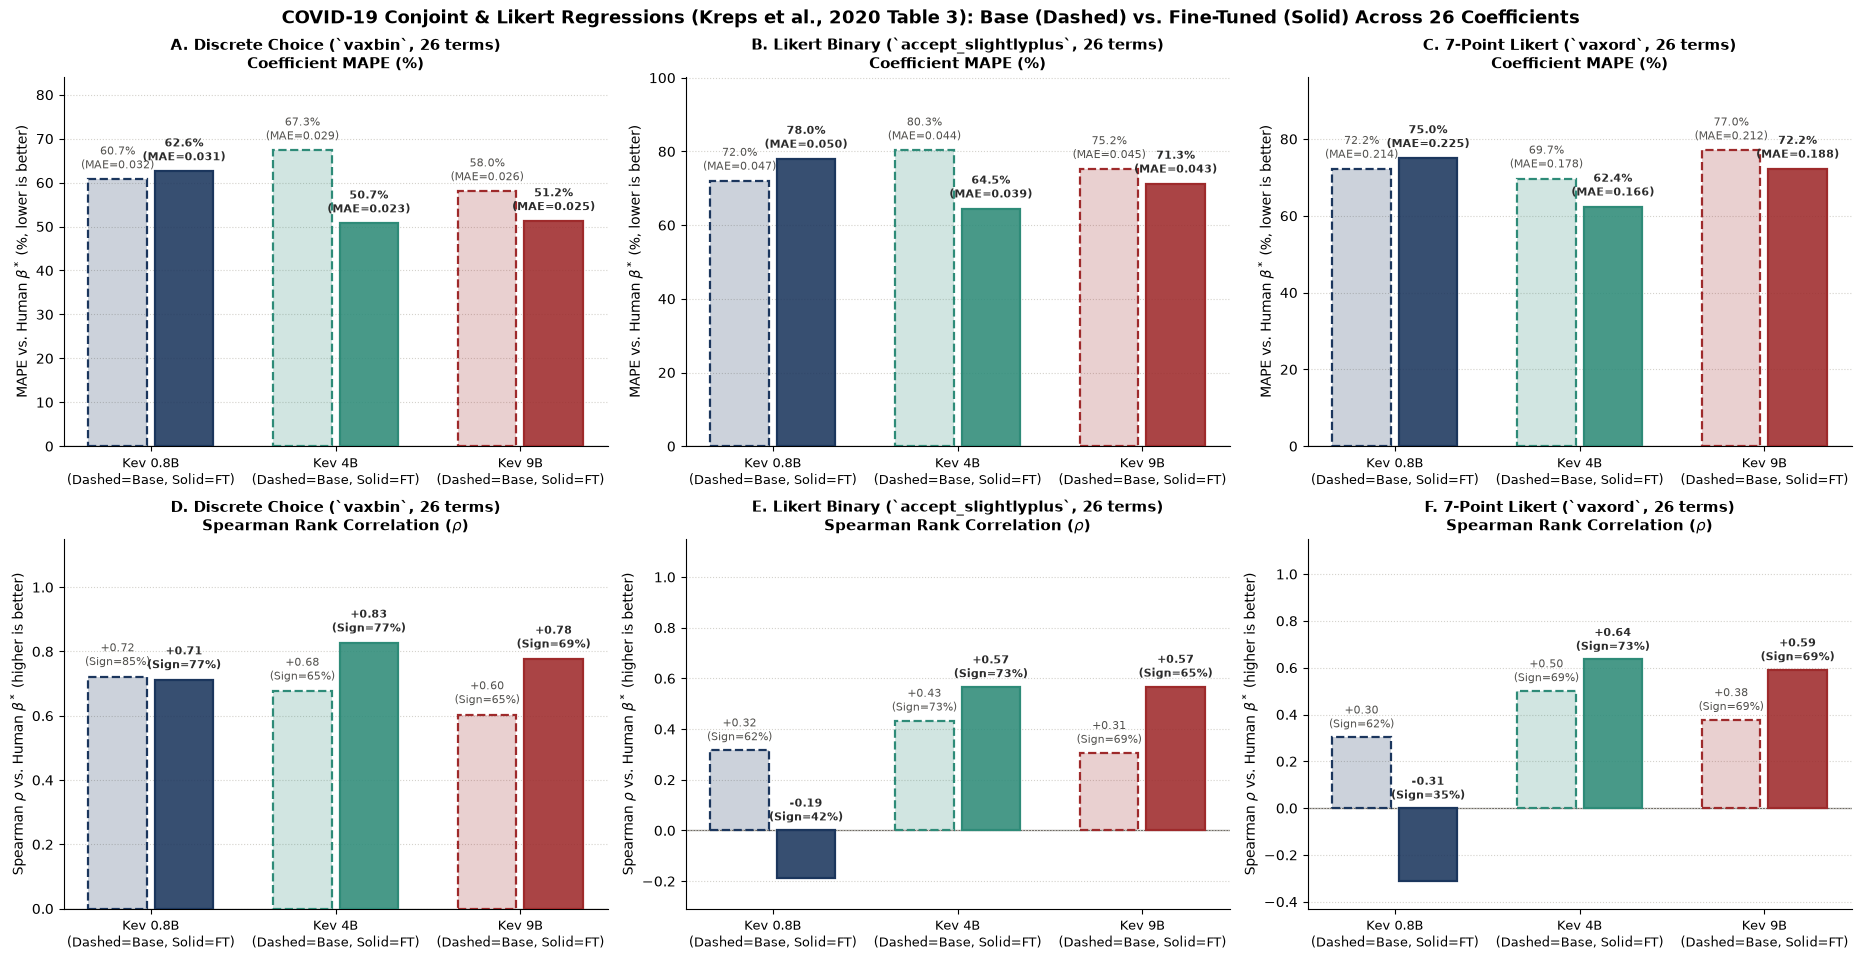

In [19]:
size_groups = [
    ("0.8B", "kev 0.8", "kev 0.8 FT", LANCET_PALETTE[0]),
    ("4B", "kev 4B", "kev 4B FT", LANCET_PALETTE[2]),
    ("9B", "kev 9B", "kev 9B FT", LANCET_PALETTE[1]),
]

fig, axes = plt.subplots(2, 3, figsize=(18.5, 9.5), constrained_layout=True)

panels = [
    # Top row: MAPE (%) (lower is better)
    (axes[0, 0], choice_all_cmp, "MAPE (%)", "A. Discrete Choice (`vaxbin`, 26 terms)\nCoefficient MAPE (%)", True),
    (axes[0, 1], accept_all_cmp, "MAPE (%)", "B. Likert Binary (`accept_slightlyplus`, 26 terms)\nCoefficient MAPE (%)", True),
    (axes[0, 2], ord_all_cmp, "MAPE (%)", "C. 7-Point Likert (`vaxord`, 26 terms)\nCoefficient MAPE (%)", True),
    # Bottom row: Spearman rank correlation rho (higher is better)
    (axes[1, 0], choice_all_cmp, "Spearman rho", "D. Discrete Choice (`vaxbin`, 26 terms)\nSpearman Rank Correlation ($\\rho$)", False),
    (axes[1, 1], accept_all_cmp, "Spearman rho", "E. Likert Binary (`accept_slightlyplus`, 26 terms)\nSpearman Rank Correlation ($\\rho$)", False),
    (axes[1, 2], ord_all_cmp, "Spearman rho", "F. 7-Point Likert (`vaxord`, 26 terms)\nSpearman Rank Correlation ($\\rho$)", False),
]

gx = np.arange(len(size_groups), dtype=float)
gw = 0.36

for ax, cmp_df, metric, title, lower_better in panels:
    vals = cmp_df[metric]
    v_max = float(vals.max())
    v_min = float(vals.min())
    span = max(abs(v_max), abs(v_min), 0.1)

    for g_idx, (size_name, base_col, ft_col, color) in enumerate(size_groups):
        b_val = float(cmp_df.loc[base_col, metric])
        f_val = float(cmp_df.loc[ft_col, metric])
        b_mae = float(cmp_df.loc[base_col, "MAE"])
        f_mae = float(cmp_df.loc[ft_col, "MAE"])

        ax.bar(
            gx[g_idx] - gw / 2.0, b_val, width=gw * 0.88,
            facecolor=to_rgba(color, 0.22), edgecolor=to_rgba(color, 1.0),
            linewidth=1.6, linestyle="--", label=f"{base_col} (Base)" if ax is axes[0, 0] else None, zorder=3,
        )
        ax.bar(
            gx[g_idx] + gw / 2.0, f_val, width=gw * 0.88,
            facecolor=to_rgba(color, 0.88), edgecolor=to_rgba(color, 1.0),
            linewidth=1.6, linestyle="-", label=f"{ft_col} (FT)" if ax is axes[0, 0] else None, zorder=3,
        )

        if metric == "MAPE (%)":
            b_txt = f"{b_val:.1f}%\n(MAE={b_mae:.3f})"
            f_txt = f"{f_val:.1f}%\n(MAE={f_mae:.3f})"
            offset = span * 0.025
            ax.text(gx[g_idx] - gw / 2.0, max(b_val, 0) + offset, b_txt, ha="center", va="bottom", fontsize=7.9, color="#52514E")
            ax.text(gx[g_idx] + gw / 2.0, max(f_val, 0) + offset, f_txt, ha="center", va="bottom", fontsize=7.9, fontweight="bold", color="#2B2B2B")
        else:
            b_sign = float(cmp_df.loc[base_col, "Sign Agree (%)"])
            f_sign = float(cmp_df.loc[ft_col, "Sign Agree (%)"])
            b_txt = f"{b_val:+.2f}\n(Sign={b_sign:.0f}%)"
            f_txt = f"{f_val:+.2f}\n(Sign={f_sign:.0f}%)"
            offset = 0.025
            ax.text(gx[g_idx] - gw / 2.0, max(b_val, 0) + offset, b_txt, ha="center", va="bottom", fontsize=7.9, color="#52514E")
            ax.text(gx[g_idx] + gw / 2.0, max(f_val, 0) + offset, f_txt, ha="center", va="bottom", fontsize=7.9, fontweight="bold", color="#2B2B2B")

    ax.axhline(0.0, color="#6E6A64", linewidth=0.9, zorder=1)
    ax.set_xticks(gx)
    ax.set_xticklabels([f"Kev {s[0]}\n(Dashed=Base, Solid=FT)" for s in size_groups], fontsize=9.5)
    ax.set_title(title, fontsize=11, fontweight="bold")
    if metric == "MAPE (%)":
        ax.set_ylabel("MAPE vs. Human $\\beta^*$ (%, lower is better)", fontsize=9.8)
        ax.set_ylim(0, v_max * 1.25)
    else:
        ax.set_ylabel("Spearman $\\rho$ vs. Human $\\beta^*$ (higher is better)", fontsize=9.8)
        ax.set_ylim(min(0.0, v_min - 0.12), 1.15)
    ax.grid(axis="y", color="#D4D2CC", linestyle=":", zorder=0)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle(
    "COVID-19 Conjoint & Likert Regressions (Kreps et al., 2020 Table 3): Base (Dashed) vs. Fine-Tuned (Solid) Across 26 Coefficients",
    fontsize=13, fontweight="bold",
)
plt.show()

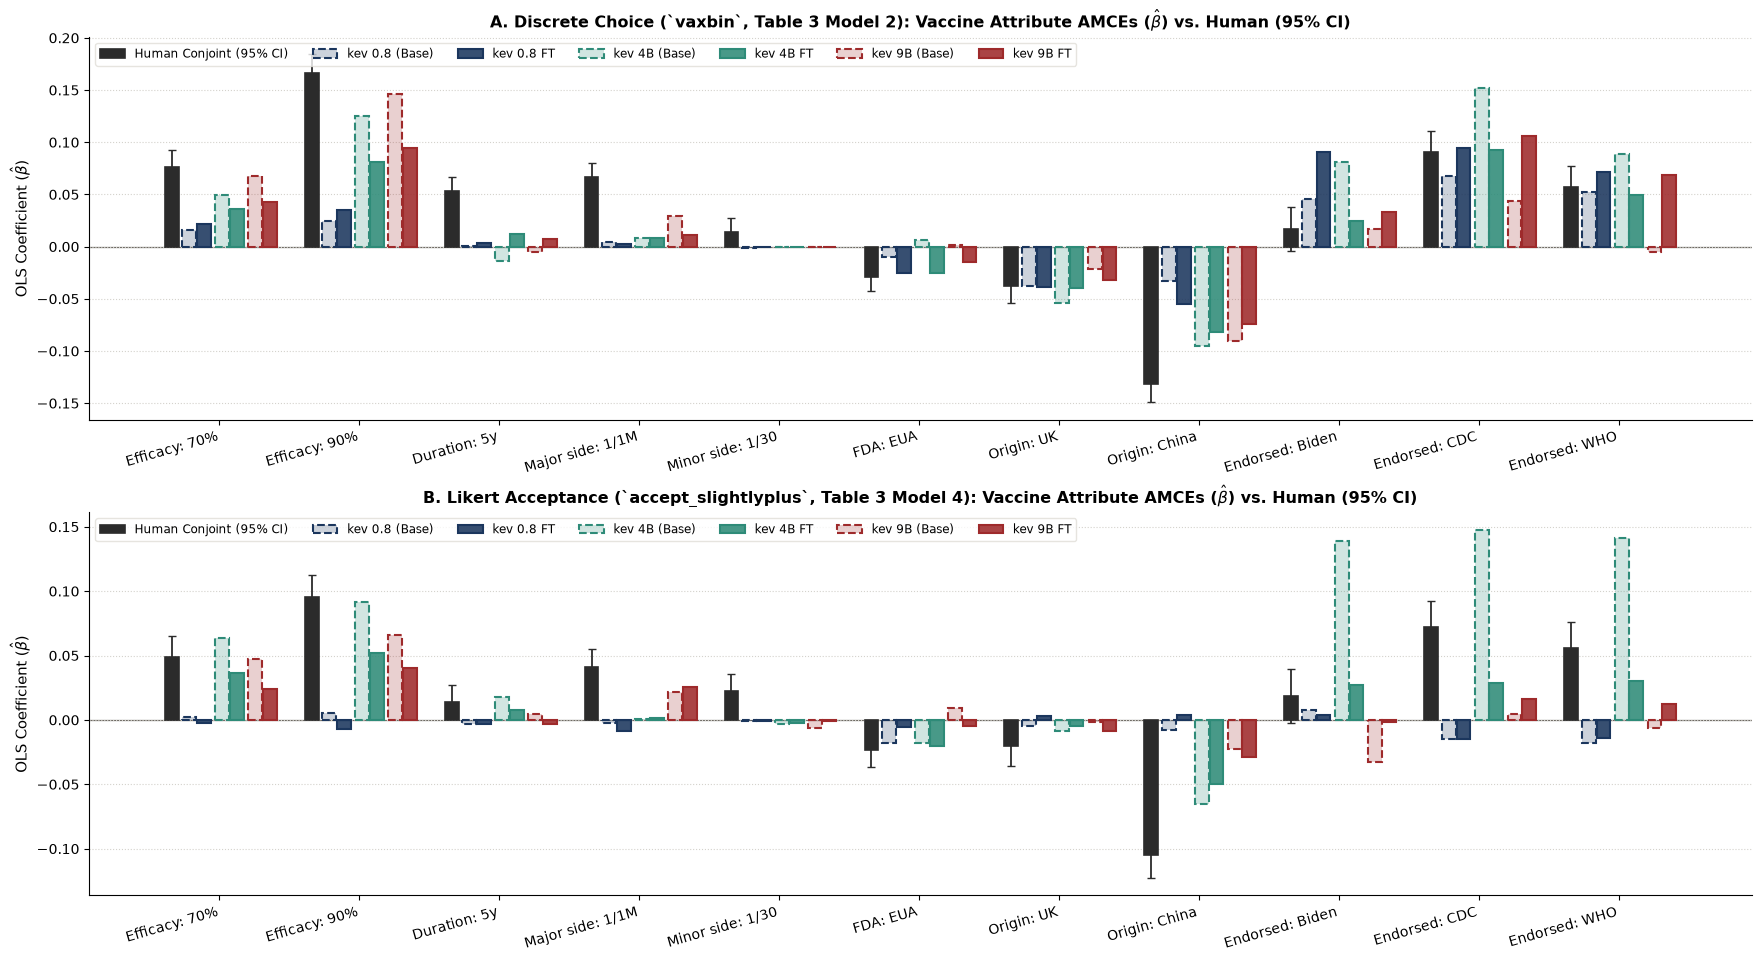

In [20]:
# Feature-level coefficient comparison: Vaccine Attribute AMCEs (11 terms) for Choice (`vaxbin`) and Likert (`accept_slightlyplus`)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(17.5, 9.5), constrained_layout=True)

x = np.arange(len(attr_lbls), dtype=float)
bar_w = 0.105
pair_gap = 0.025
slot_offsets = [
    -3.25 * bar_w,
    -2.05 * bar_w, -1.05 * bar_w,
    -0.05 * bar_w + pair_gap, 0.95 * bar_w + pair_gap,
    1.95 * bar_w + 2 * pair_gap, 2.95 * bar_w + 2 * pair_gap,
]

short_attr_labels = [
    "Efficacy: 70%",
    "Efficacy: 90%",
    "Duration: 5y",
    "Major side: 1/1M",
    "Minor side: 1/30",
    "FDA: EUA",
    "Origin: UK",
    "Origin: China",
    "Endorsed: Biden",
    "Endorsed: CDC",
    "Endorsed: WHO",
]

for ax, b_df, se_df, panel_title in [
    (ax1, m2_beta.loc[attr_lbls], m2_se.loc[attr_lbls], "A. Discrete Choice (`vaxbin`, Table 3 Model 2): Vaccine Attribute AMCEs ($\\hat{\\beta}$) vs. Human (95% CI)"),
    (ax2, m4_beta.loc[attr_lbls], m4_se.loc[attr_lbls], "B. Likert Acceptance (`accept_slightlyplus`, Table 3 Model 4): Vaccine Attribute AMCEs ($\\hat{\\beta}$) vs. Human (95% CI)"),
]:
    h_pos = x + slot_offsets[0]
    ax.bar(
        h_pos, b_df["human"].values, width=bar_w * 0.94,
        facecolor="#2B2B2B", edgecolor="#2B2B2B", linewidth=1.2,
        label="Human Conjoint (95% CI)", zorder=3,
    )
    ax.errorbar(
        h_pos, b_df["human"].values, yerr=1.96 * se_df["human"].values,
        fmt="none", ecolor="#2B2B2B", elinewidth=1.3, capsize=2.8, zorder=4,
    )

    for g_idx, (size_name, base_col, ft_col, color) in enumerate(size_groups):
        base_pos = x + slot_offsets[1 + 2 * g_idx]
        ft_pos = x + slot_offsets[2 + 2 * g_idx]
        ax.bar(
            base_pos, b_df[base_col].values, width=bar_w * 0.94,
            facecolor=to_rgba(color, 0.22), edgecolor=to_rgba(color, 1.0),
            linewidth=1.5, linestyle="--", label=f"{base_col} (Base)", zorder=3,
        )
        ax.bar(
            ft_pos, b_df[ft_col].values, width=bar_w * 0.94,
            facecolor=to_rgba(color, 0.88), edgecolor=to_rgba(color, 1.0),
            linewidth=1.5, linestyle="-", label=ft_col, zorder=3,
        )

    ax.axhline(0.0, color="#6E6A64", linewidth=0.9, zorder=1)
    ax.set_xticks(x)
    ax.set_xticklabels(short_attr_labels, rotation=16, ha="right", fontsize=9.8)
    ax.set_ylabel("OLS Coefficient ($\\hat{\\beta}$)", fontsize=10.5)
    ax.set_title(panel_title, fontsize=11.5, fontweight="bold")
    ax.grid(axis="y", color="#D4D2CC", linestyle=":", zorder=0)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.legend(ncol=7, frameon=True, edgecolor="#E0DED8", fontsize=8.8, loc="upper left")

plt.show()